# Molecular Orbitals of Water

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4v2/blob/main/temp/09-molecular-orbitals.ipynb)
:::


In [1]:
####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path
import sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Psi4 cannot be installed with pip. On Colab we first install conda
# (condacolab), which RESTARTS the session. After the restart, run
# this cell again and Psi4 will be installed with conda.
try:
    import psi4
except ImportError:
    if IN_COLAB:
        !pip -q install condacolab
        import condacolab
        condacolab.install()
        !mamba install -q -y -c conda-forge psi4
    import psi4

try:
    import py3Dmol
except ImportError:
    !pip -q install py3Dmol
    import py3Dmol

try:
    import skimage          # scikit-image draws the static orbital and density surfaces
except ImportError:
    !pip -q install scikit-image
    import skimage

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Style sheets and helper functions from the book's GitHub repository
if IN_COLAB:
    if not Path("styles/tufte.mplstyle").exists():
        !wget -q -N -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/styles/tufte.mplstyle
        !wget -q -N https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/psi4_helpers.py
    plt.style.use("styles/tufte.mplstyle")
    nproc = 2          # Colab gives you 2 cores
else:
    sys.path.insert(0, "..")                    # psi4_helpers.py is one folder up
    plt.style.use("../styles/tufte.mplstyle")
    nproc = 4          # house limit: 4 threads

import psi4_helpers as ph

# 3D pictures: False = static images (as in the book); True = rotatable py3Dmol viewers
INTERACTIVE = False

# All Psi4 .out and .log files go into the output folder
output_dir = Path("output")
output_dir.mkdir(exist_ok=True)

# Resources: house limits are 4 threads and 4 GB
psi4.set_num_threads(nproc)
_ = psi4.set_memory("2 GB")


  Threads set to 4 by Python driver.



  Memory set to   1.863 GiB by Python driver.


Hartree–Fock and DFT build the wavefunction from **molecular orbitals** (MOs). *Psi4* gives us their energies and shapes. In this notebook we look at the **canonical** MOs (the ones the calculation produces directly) and then at **localized** MOs, which look like the bonds and lone pairs of a Lewis structure.

## What You Will Learn
- How to get orbital **energies**, **occupations** and **symmetry labels** from a wavefunction.
- How to compare orbital energies with **photoelectron spectroscopy** using Koopmans' theorem.
- How to draw orbitals from **cube files** in the notebook.
- How to **localize** the orbitals (Boys and Pipek–Mezey) and why the canonical and localized pictures describe the same molecule.

In [2]:
psi4.set_output_file("output/09-molecular-orbitals.out", False);
cube_dir = output_dir / "mo_cubes"
cube_dir.mkdir(exist_ok=True)
h2eV = psi4.constants.hartree2ev

## 1. The Calculation

```{note} Psi4 settings in this cell
:class: dropdown
`hf/cc-pvdz`
: Hartree–Fock orbitals have a clear meaning through **Koopmans' theorem**: minus the energy of an occupied orbital approximates the energy needed to remove an electron from it. *Alternatives:* DFT orbitals (`b3lyp`) have very similar shapes, but their energies are systematically too high (too small ionization energies) and should not be used with Koopmans' theorem. `hf/6-31g*` gives almost identical pictures.

`scf_type: "pk"`
: Exact integrals, so the orbital energies can be compared with other programs.
```

In [3]:
water = psi4.geometry("""
0 1
O
H 1 0.9578
H 1 0.9578 2 104.48
""")
psi4.set_options({"basis": "cc-pvdz", "scf_type": "pk"})
E, wfn = psi4.energy("hf", molecule=water, return_wfn=True)

## 2. Orbital Energies and Symmetry Labels

Because water has $C_{2v}$ symmetry, *Psi4* stores the orbitals by **irreducible representation** ($a_1$, $a_2$, $b_1$, $b_2$). We collect them, sort by energy and number them within each symmetry, giving the standard labels $1a_1$, $2a_1$, $1b_2$, …

In [4]:
char_table = water.point_group().char_table()
ndocc = wfn.doccpi()                 # doubly occupied orbitals in each irrep

orbitals = []
for h in range(wfn.nirrep()):
    irrep = char_table.gamma(h).symbol().lower()
    for i, eps in enumerate(wfn.epsilon_a().nph[h]):
        orbitals.append({"label": f"{i + 1}{irrep}", "energy (hartree)": eps,
                         "occupied": i < ndocc[h]})

mo_table = pd.DataFrame(orbitals).sort_values("energy (hartree)").reset_index(drop=True)
mo_table["energy (eV)"] = mo_table["energy (hartree)"] * h2eV
mo_table.head(8).round(3)

,label,energy (hartree),occupied,energy (eV)
0,1a1,-20.551,True,-559.209
1,2a1,-1.336,True,-36.366
2,1b2,-0.699,True,-19.019
3,3a1,-0.567,True,-15.416
4,1b1,-0.493,True,-13.418
5,4a1,0.185,False,5.047
6,2b2,0.256,False,6.971
7,3b2,0.789,False,21.465


Water has 10 electrons in 5 doubly occupied orbitals: $1a_1$ (the O 1s core), $2a_1$, $1b_2$, $3a_1$ and $1b_1$ (the HOMO). The lowest empty orbital (LUMO) is $4a_1$.

### An orbital energy diagram

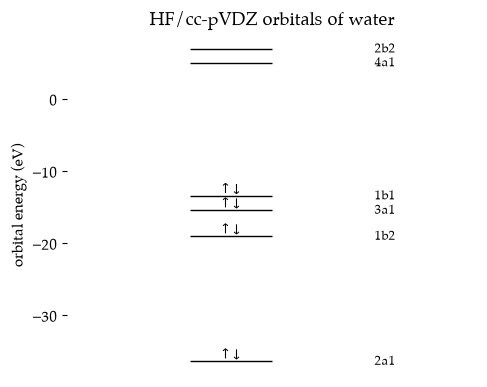

In [5]:
show = mo_table.iloc[1:7]          # skip the very deep 1s core orbital so the valence levels are visible

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,4))
for _, row in show.iterrows():
    ax.hlines(row["energy (eV)"], 0.3, 0.5, color="black", linewidth=1.0)
    ax.text(0.75, row["energy (eV)"], row["label"], va="center", fontsize=9)
    if row["occupied"]:
        ax.text(0.4, row["energy (eV)"], "↑↓", ha="center", va="bottom", fontsize=9, fontfamily="DejaVu Sans")
ax.set_xlim(0, 1)
ax.set_xticks([])
ax.set_ylabel("orbital energy (eV)")
ax.set_title("HF/cc-pVDZ orbitals of water")
plt.show()

## 3. Koopmans' Theorem and Photoelectron Spectroscopy

The photoelectron spectrum of water shows four valence ionizations. We compare them with $-\varepsilon$ for each occupied orbital.

In [6]:
pes = {"1b1": 12.62, "3a1": 14.74, "1b2": 18.51, "2a1": 32.2}     # vertical ionization energies, eV

occ = mo_table[mo_table["occupied"]].set_index("label")
koopmans = pd.DataFrame({
    "-epsilon (eV)": [-occ.loc[k, "energy (eV)"] for k in pes],
    "experiment (eV)": list(pes.values()),
}, index=list(pes.keys()))
koopmans["difference (eV)"] = koopmans["-epsilon (eV)"] - koopmans["experiment (eV)"]
koopmans.round(2)

,-epsilon (eV),experiment (eV),difference (eV)
1b1,13.42,12.62,0.80
3a1,15.42,14.74,0.68
1b2,19.02,18.51,0.51
2a1,36.37,32.20,4.17


The **order** is right, and the three outer valence orbitals are within about 0.5–0.8 eV of experiment. The deep $2a_1$ orbital is about 4 eV too high. Koopmans' theorem ignores two effects that partly cancel: the other electrons relax when one is removed, and electron correlation is missing from HF. For deeper orbitals the relaxation is larger and the cancellation fails.

Note that the spectrum shows **two different lone-pair ionizations** ($1b_1$ at 12.6 eV and $3a_1$ at 14.7 eV). We return to this below.

## 4. Drawing the Canonical Orbitals

```{note} Psi4 settings for orbital cubes
:class: dropdown
`cubeprop_tasks: ["orbitals"]` with `cubeprop_orbitals: [2, 3, 4, 5, 6]`
: Writes one cube per orbital. Orbitals are numbered from 1 in order of energy; positive numbers are alpha orbitals, negative numbers beta. Without `cubeprop_orbitals`, every orbital is written, which gives many large files. *Alternative:* `["frontier_orbitals"]` writes just the HOMO and LUMO.

Exporting to other programs
: `psi4.molden(wfn, "output/water.molden")` writes all orbitals in a format that *Jmol*, *Avogadro* and *IQmol* can read.
```

In [7]:
psi4.set_options({"cubeprop_tasks": ["orbitals"],
                  "cubeprop_orbitals": [2, 3, 4, 5, 6],
                  "cubeprop_filepath": str(cube_dir)})
psi4.cubeprop(wfn)
psi4.molden(wfn, str(output_dir / "water.molden"))
print(sorted(p.name for p in cube_dir.glob("Psi_a_*.cube")))

['Psi_a_2_2-A1.cube', 'Psi_a_3_1-B2.cube', 'Psi_a_4_3-A1.cube', 'Psi_a_5_1-B1.cube', 'Psi_a_6_4-A1.cube']


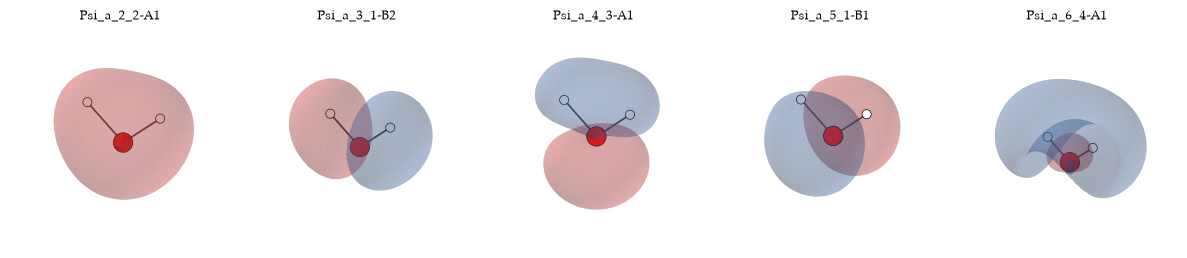

In [8]:
mo_cubes = sorted(cube_dir.glob("Psi_a_*.cube"), key=lambda p: int(p.name.split("_")[2]))
ph.show_orbitals(mo_cubes, titles=[p.stem for p in mo_cubes], mol=water, interactive=INTERACTIVE, transparency=0.75)

The canonical orbitals are spread over the whole molecule and each has the symmetry of the molecule:

- $2a_1$: mostly O 2s, bonding to both H.
- $1b_2$: O 2p in the molecular plane, bonding to both H. It is the main O–H bonding orbital.
- $3a_1$: O 2p along the $C_2$ axis mixed with 2s; partly bonding, partly an **in-plane lone pair**.
- $1b_1$ (HOMO): a pure O 2p orbital perpendicular to the plane. It is an **out-of-plane lone pair** with no H character at all.
- $4a_1$ (LUMO): antibonding between O and H.

## 5. Localized Orbitals: Bonds and Lone Pairs

Any set of occupied orbitals can be mixed (rotated) among themselves without changing the total wavefunction, the electron density or the energy. **Localization** chooses the mixture that makes each orbital as compact as possible.

```{note} Psi4 settings: localization
:class: dropdown
`psi4.core.Localizer.build("BOYS", basis, C_occ)`
: **Boys** localization makes the orbital centres as far apart as possible. It is the classic method and tends to give the familiar "rabbit-ear" lone pairs.

`"PIPEK_MEZEY"`
: Maximizes the charge each orbital puts on as few atoms as possible. It keeps $\sigma$ and $\pi$ separation in planar molecules and can give a different description of lone pairs.

Other options
: Intrinsic bond orbitals (IBOs) are popular in teaching but are not part of standard *Psi4*. **Natural bond orbitals** (NBO) need the separate NBO program.

`wfn.Ca_subset("AO", "OCC")`
: The occupied orbital coefficients in the atomic-orbital basis, without symmetry blocking. Localized orbitals break the symmetry, so we must work without it.
```

In [9]:
C_occ = wfn.Ca_subset("AO", "OCC")
cube_props = psi4.core.CubeProperties(wfn)

localized = {}
for method in ["BOYS", "PIPEK_MEZEY"]:
    loc = psi4.core.Localizer.build(method, wfn.basisset(), C_occ)
    loc.localize()
    localized[method] = loc.L
    labels = [f"{method}{i + 1}" for i in range(loc.L.cols())]
    cube_props.compute_orbitals(loc.L, list(range(loc.L.cols())), labels, "LMO")

print(sorted(p.name for p in cube_dir.glob("LMO_*.cube")))

['LMO_1_BOYS1.cube', 'LMO_1_PIPEK_MEZEY1.cube', 'LMO_2_BOYS2.cube', 'LMO_2_PIPEK_MEZEY2.cube', 'LMO_3_BOYS3.cube', 'LMO_3_PIPEK_MEZEY3.cube', 'LMO_4_BOYS4.cube', 'LMO_4_PIPEK_MEZEY4.cube', 'LMO_5_BOYS5.cube', 'LMO_5_PIPEK_MEZEY5.cube']


In [10]:
F_ao = wfn.Fa_subset("AO").np               # Fock matrix in the AO basis (matches L's rows)

L = localized["BOYS"].np
F_lmo = L.T @ F_ao @ L                      # Fock matrix in the LMO basis

lmo_table = pd.DataFrame({"energy (hartree)": np.diag(F_lmo)},
                         index=[f"Boys LMO {i+1}" for i in range(L.shape[1])])
lmo_table["energy (eV)"] = lmo_table["energy (hartree)"] * h2eV
lmo_table.round(3)

,energy (hartree),energy (eV)
Boys LMO 1,-20.419,-555.622
Boys LMO 2,-0.904,-24.600
Boys LMO 3,-0.904,-24.600
Boys LMO 4,-0.709,-19.304
Boys LMO 5,-0.709,-19.304


The same density, two descriptions: we check that the density built from the localized orbitals equals the canonical density.

In [11]:
C = C_occ.np
for method, L in localized.items():
    diff = np.abs(C @ C.T - L.np @ L.np.T).max()
    print(f"{method:12s} largest difference in the density matrix: {diff:.1e}")

BOYS         largest difference in the density matrix: 6.7e-16
PIPEK_MEZEY  largest difference in the density matrix: 4.4e-16


### Boys localized orbitals

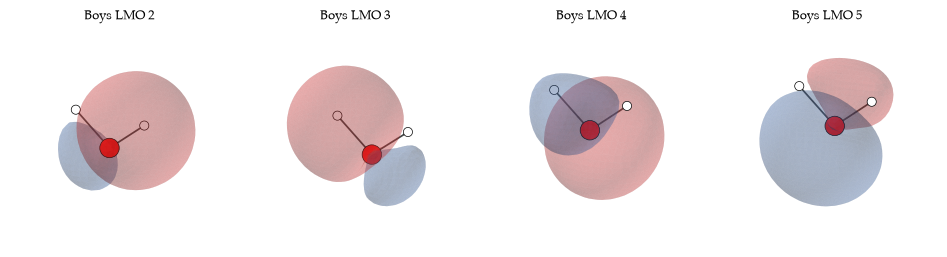

In [12]:
lmos = range(2, 6)          # orbital 1 is the O 1s core
ph.show_orbitals([cube_dir / f"LMO_{i}_BOYS{i}.cube" for i in lmos],
                 titles=[f"Boys LMO {i}" for i in lmos], mol=water, interactive=INTERACTIVE, transparency=0.75)

Boys localization gives two equivalent **O–H bonds** and two equivalent **lone pairs** pointing above and below the molecular plane: the $sp^3$-like "rabbit ears" of the textbook picture.

### Pipek–Mezey localized orbitals

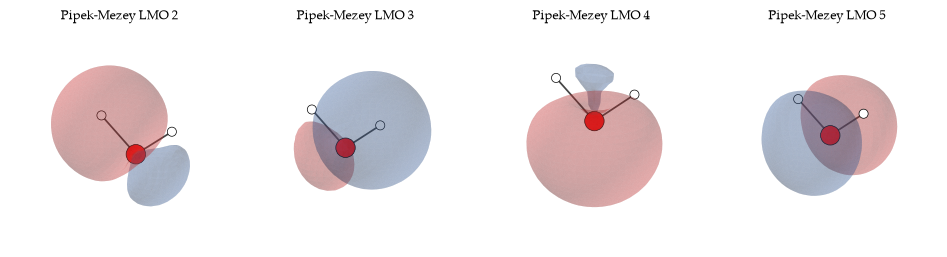

In [13]:
ph.show_orbitals([cube_dir / f"LMO_{i}_PIPEK_MEZEY{i}.cube" for i in lmos],
                 titles=[f"Pipek-Mezey LMO {i}" for i in lmos], mol=water, interactive=INTERACTIVE, transparency=0.75)

Pipek–Mezey gives the same two O–H bonds, but the lone pairs are different: one **$\sigma$-type** lone pair in the molecular plane (pointing away from the hydrogens, $sp$-like) and one **$\pi$-type** lone pair, a pure $p$ orbital perpendicular to the plane.

We can confirm this with numbers instead of pictures. The **centroid** of an orbital is the average position of its electron, $\langle \mathbf{r} \rangle$, calculated from the dipole integrals. In *Psi4*'s orientation, water lies in the $yz$ plane, so an orbital centred off the plane has a non-zero $x$ value.

In [14]:
mints = psi4.core.MintsHelper(wfn.basisset())
dipole_ints = [m.np for m in mints.ao_dipole()]          # x, y, z integrals in the AO basis

for method, L in localized.items():
    L = L.np
    rows = []
    for i in range(L.shape[1]):
        centroid = [-(L[:, i] @ d @ L[:, i]) * psi4.constants.bohr2angstroms for d in dipole_ints]
        rows.append(np.round(centroid, 3))
    print(method)
    print(pd.DataFrame(rows, columns=["x (Å)", "y (Å)", "z (Å)"], index=[f"LMO {i+1}" for i in range(L.shape[1])]))
    print()

BOYS
       x (Å)  y (Å)  z (Å)
LMO 1 -0.000  0.000 -0.065
LMO 2 -0.000  0.411  0.271
LMO 3 -0.000 -0.411  0.271
LMO 4 -0.262 -0.000 -0.216
LMO 5  0.262  0.000 -0.216

PIPEK_MEZEY
       x (Å)  y (Å)  z (Å)
LMO 1   -0.0 -0.000 -0.079
LMO 2   -0.0 -0.409  0.271
LMO 3   -0.0  0.409  0.271
LMO 4   -0.0 -0.000 -0.377
LMO 5   -0.0 -0.000 -0.042



In the Boys set, two orbitals sit at $x = \pm 0.26$ Å: the rabbit ears above and below the plane. In the Pipek–Mezey set every centroid has $x = 0$; the $\pi$ lone pair is centred on the oxygen itself because its two lobes cancel.

```{important} Which picture is "right"?
Both. The canonical orbitals, the Boys orbitals and the Pipek–Mezey orbitals are different ways of dividing up **the same** wavefunction; the density matrix check above shows they are identical to rounding error ($10^{-16}$). They differ in what they make easy to see:

- The **canonical** orbitals have definite energies, so they explain the photoelectron spectrum with its **two different** lone-pair ionizations.
- **Localized** orbitals look like a Lewis structure and help explain the direction of bonds and hydrogen bonds.

Whether the textbook "rabbit-ear" lone pairs should be taught at all has been debated in the education literature: Clauss *et al.*, *Chem. Educ. Res. Pract.* **2014**, *15*, 417 ([doi:10.1039/C4RP00057A](https://doi.org/10.1039/C4RP00057A)); Hiberty, Danovich and Shaik, *Chem. Educ. Res. Pract.* **2015**, *16*, 689 ([doi:10.1039/C4RP00245H](https://doi.org/10.1039/C4RP00245H)); and the reply by Clauss *et al.*, *Chem. Educ. Res. Pract.* **2015**, *16*, 694 ([doi:10.1039/C5RP00061K](https://doi.org/10.1039/C5RP00061K)).
```

## Summary
- Orbital energies, occupations and symmetry labels come directly from the wavefunction.
- Koopmans' theorem links HF orbital energies to the photoelectron spectrum.
- `psi4.cubeprop()` writes orbitals to cube files, which we can draw as fixed pictures or as rotatable 3D surfaces (`INTERACTIVE = True`).
- Localization turns delocalized canonical MOs into bonds and lone pairs without changing the wavefunction.